# DSC640 Milestone 5: Childcare Prices and Affordability

**Student:** Anil Bammidi  
**Course:** DSC640 Data Presentation & Visualization  
**Date:** August 19, 2026  

This notebook reproduces the final project analysis and dashboard from the National Database of Childcare Prices. The story focuses on the change in weekly center-based childcare prices from 2008 through 2018, geographic differences in 2018, and the relationship between infant-care prices and county median household income.

**Call to action:** Use local price and household-income context to target childcare assistance, provider support, and outcome measurement where the burden is greatest.


## 1. Setup and portable file locations

Place this notebook, the original Excel workbook, and the two processed CSV files in the same folder. The notebook attempts to read the original workbook first. If the workbook cannot be opened, it uses the processed CSVs submitted with the project.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

BASE_DIR = Path.cwd()
ORIGINAL_FILE = BASE_DIR / "data" / "nationaldatabaseofchildcareprices(1).xlsx"
STATE_FILE = BASE_DIR / "data" / "Anil_Bammidi_DSC640_Childcare_State_Metrics.csv"
TREND_FILE = BASE_DIR / "data" / "Anil_Bammidi_DSC640_Childcare_Trend_Metrics.csv"

# When this notebook is executed from another directory, also check the notebook's
# common output location used during development.
if not STATE_FILE.exists():
    STATE_FILE = BASE_DIR / "output" / "milestone5" / STATE_FILE.name
if not TREND_FILE.exists():
    TREND_FILE = BASE_DIR / "output" / "milestone5" / TREND_FILE.name

COLORS = {
    "navy": "#17324D",
    "blue": "#4472C4",
    "teal": "#2A9D8F",
    "coral": "#E76F51",
    "gold": "#E9C46A",
    "cream": "#F7F3EA",
    "muted": "#64748B",
}

plt.rcParams.update({
    "figure.figsize": (12, 7),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
    "axes.titleweight": "bold",
})


## 2. Load, clean, and transform the data

The analysis uses the median of reported county median weekly prices. Annualized figures are calculated as weekly price multiplied by 52. The affordability burden is calculated as annualized infant-care price divided by median household income. Missing prices are retained as missing; they are not imputed.


In [2]:
COST_COLS = ["MCInfant", "MCToddler", "MCPreschool"]


def build_metrics_from_original(path):
    raw = pd.read_excel(path)
    required = {"StudyYear", "State_Name", "State_Abbreviation", "MHI"}.union(COST_COLS)
    missing = sorted(required.difference(raw.columns))
    if missing:
        raise ValueError("Original workbook is missing required columns: " + ", ".join(missing))

    data = raw.copy()
    data["StudyYear"] = pd.to_numeric(data["StudyYear"], errors="coerce")
    data = data[data["StudyYear"].between(2008, 2018)].copy()
    for column in COST_COLS + ["MHI"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    trend = (
        data.groupby("StudyYear", as_index=False)[COST_COLS]
        .median()
        .sort_values("StudyYear")
    )

    latest = data[data["StudyYear"] == 2018].copy()
    grouped = latest.groupby(["State_Name", "State_Abbreviation"], as_index=False)
    state = grouped[COST_COLS + ["MHI"]].median()
    state["counties"] = grouped.size()["size"].to_numpy()
    state = state.rename(columns={
        "MCInfant": "infant",
        "MCToddler": "toddler",
        "MCPreschool": "preschool",
        "MHI": "mhi",
    })
    state["annual_infant"] = state["infant"] * 52
    state["burden"] = state["annual_infant"] / state["mhi"]
    return data, state, trend


try:
    raw_data, state_metrics, trend_metrics = build_metrics_from_original(ORIGINAL_FILE)
    source_mode = "Original Excel workbook"
except Exception as exc:
    raw_data = None
    state_metrics = pd.read_csv(STATE_FILE)
    trend_metrics = pd.read_csv(TREND_FILE)
    source_mode = "Processed project CSVs"
    print("Original workbook was not used:", exc)

state_metrics = state_metrics.sort_values("State_Name").reset_index(drop=True)
trend_metrics = trend_metrics.sort_values("StudyYear").reset_index(drop=True)

print("Source mode:", source_mode)
print("Years:", int(trend_metrics["StudyYear"].min()), "to", int(trend_metrics["StudyYear"].max()))
print("Jurisdictions represented:", len(state_metrics))
print("Jurisdictions with a reported 2018 infant-care price:", int(state_metrics["infant"].notna().sum()))


Original workbook was not used: [Errno 2] No such file or directory: '/Users/anil/Desktop/Bellevue/DSC640/Milestone 5/nationaldatabaseofchildcareprices(1).xlsx'
Source mode: Processed project CSVs
Years: 2008 to 2018
Jurisdictions represented: 51
Jurisdictions with a reported 2018 infant-care price: 41


In [3]:
# Reconciliation checks used in the final presentation
infant_2008 = float(trend_metrics.loc[trend_metrics["StudyYear"] == 2008, "MCInfant"].iloc[0])
infant_2018 = float(trend_metrics.loc[trend_metrics["StudyYear"] == 2018, "MCInfant"].iloc[0])
growth = infant_2018 / infant_2008 - 1
annual_2018 = infant_2018 * 52

assert round(infant_2008, 2) == 120.64
assert round(infant_2018, 2) == 153.60
assert round(growth * 100) == 27

pd.DataFrame({
    "Measure": [
        "2008 median weekly infant-care price",
        "2018 median weekly infant-care price",
        "Increase over study period",
        "Annualized 2018 price",
    ],
    "Value": [f"${infant_2008:,.2f}", f"${infant_2018:,.2f}", f"{growth:.1%}", f"${annual_2018:,.0f}"],
})


,Measure,Value
0,2008 median weekly infant-care price,$120.64
1,2018 median weekly infant-care price,$153.60
2,Increase over study period,27.3%
3,Annualized 2018 price,"$7,987"


## 3. Visual 1 - price trend by age group

The line chart shows that the median weekly price increased for infant, toddler, and preschool center-based care. Infant care remained the most expensive and increased approximately 27% between 2008 and 2018.


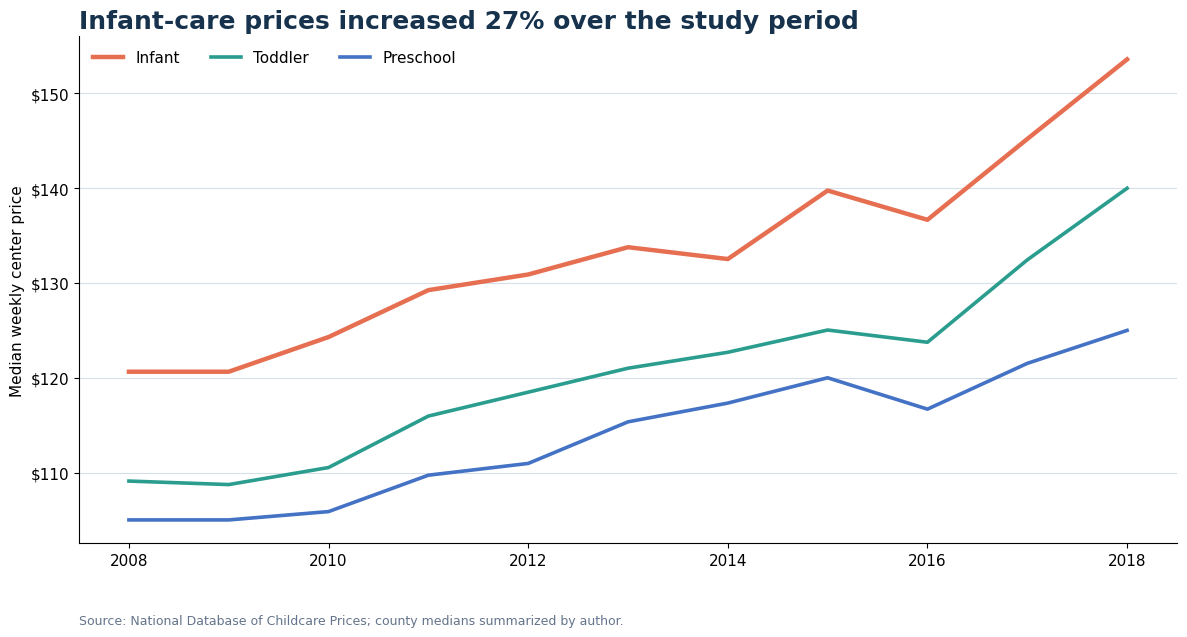

In [4]:
fig, ax = plt.subplots(figsize=(12, 6.5))
series = [
    ("MCInfant", "Infant", COLORS["coral"], 3.2),
    ("MCToddler", "Toddler", COLORS["teal"], 2.6),
    ("MCPreschool", "Preschool", COLORS["blue"], 2.6),
]
for column, label, color, width in series:
    ax.plot(
        trend_metrics["StudyYear"].to_numpy(),
        trend_metrics[column].to_numpy(),
        label=label,
        color=color,
        linewidth=width,
    )

ax.set_title("Infant-care prices increased 27% over the study period", loc="left", fontsize=18, color=COLORS["navy"])
ax.set_ylabel("Median weekly center price")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(True, axis="y", color="#D8DEE8", linewidth=0.8)
ax.xaxis.grid(False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.text(0, -0.16, "Source: National Database of Childcare Prices; county medians summarized by author.",
        transform=ax.transAxes, fontsize=9, color=COLORS["muted"])
plt.tight_layout()
plt.show()


## 4. Visual 2 - geographic comparison

The state comparison uses 2018 median weekly infant-care prices across reporting counties. Ten jurisdictions did not have a usable 2018 infant-care value in the project extract and are not ranked. The missing values are not replaced or estimated.


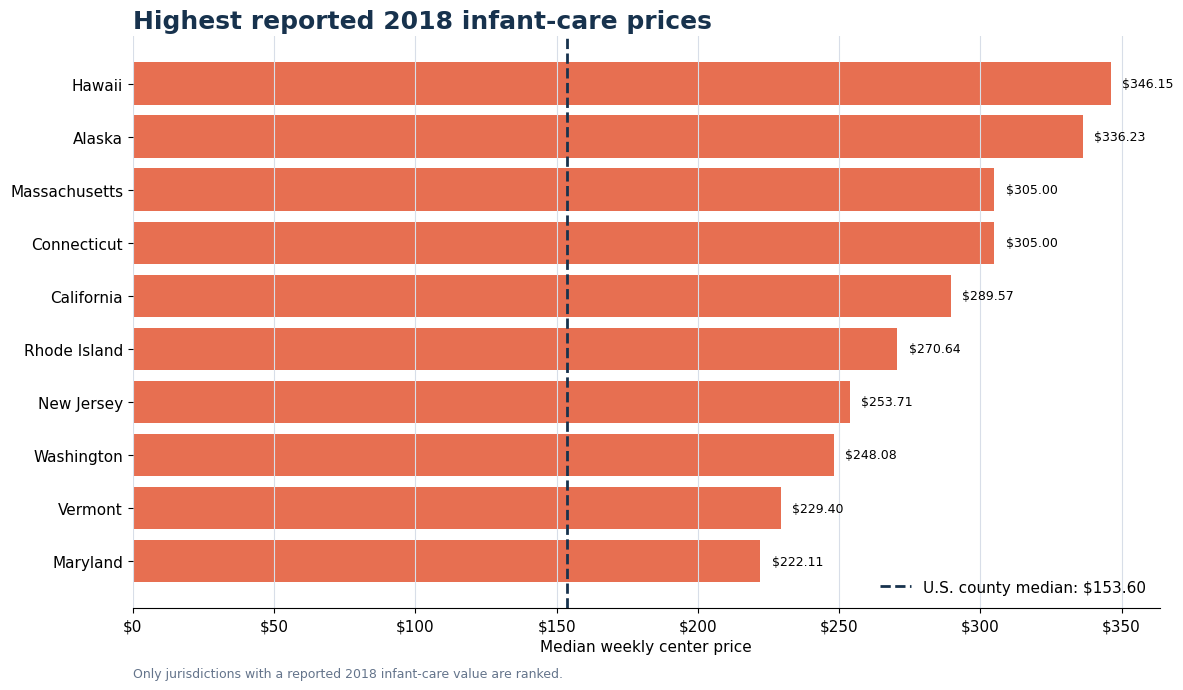

In [5]:
top_states = (
    state_metrics.dropna(subset=["infant"])
    .nlargest(10, "infant")
    .sort_values("infant")
)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    top_states["State_Name"].tolist(),
    top_states["infant"].to_numpy(),
    color=COLORS["coral"],
)
ax.axvline(infant_2018, color=COLORS["navy"], linestyle="--", linewidth=2,
           label=f"U.S. county median: ${infant_2018:,.2f}")
ax.set_title("Highest reported 2018 infant-care prices", loc="left", fontsize=18, color=COLORS["navy"])
ax.set_xlabel("Median weekly center price")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(True, axis="x", color="#D8DEE8", linewidth=0.8)
ax.yaxis.grid(False)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
for bar in bars:
    ax.text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2,
            f"${bar.get_width():,.2f}", va="center", fontsize=9)
ax.legend(frameon=False, loc="lower right")
ax.text(0, -0.12, "Only jurisdictions with a reported 2018 infant-care value are ranked.",
        transform=ax.transAxes, fontsize=9, color=COLORS["muted"])
plt.tight_layout()
plt.show()


## 5. Visual 3 - final Illinois dashboard view

The dashboard view combines a local price, annualized cost, affordability burden, county coverage, and an age-group comparison. Illinois is used as an illustrative state profile, not as a claim about every Illinois household.


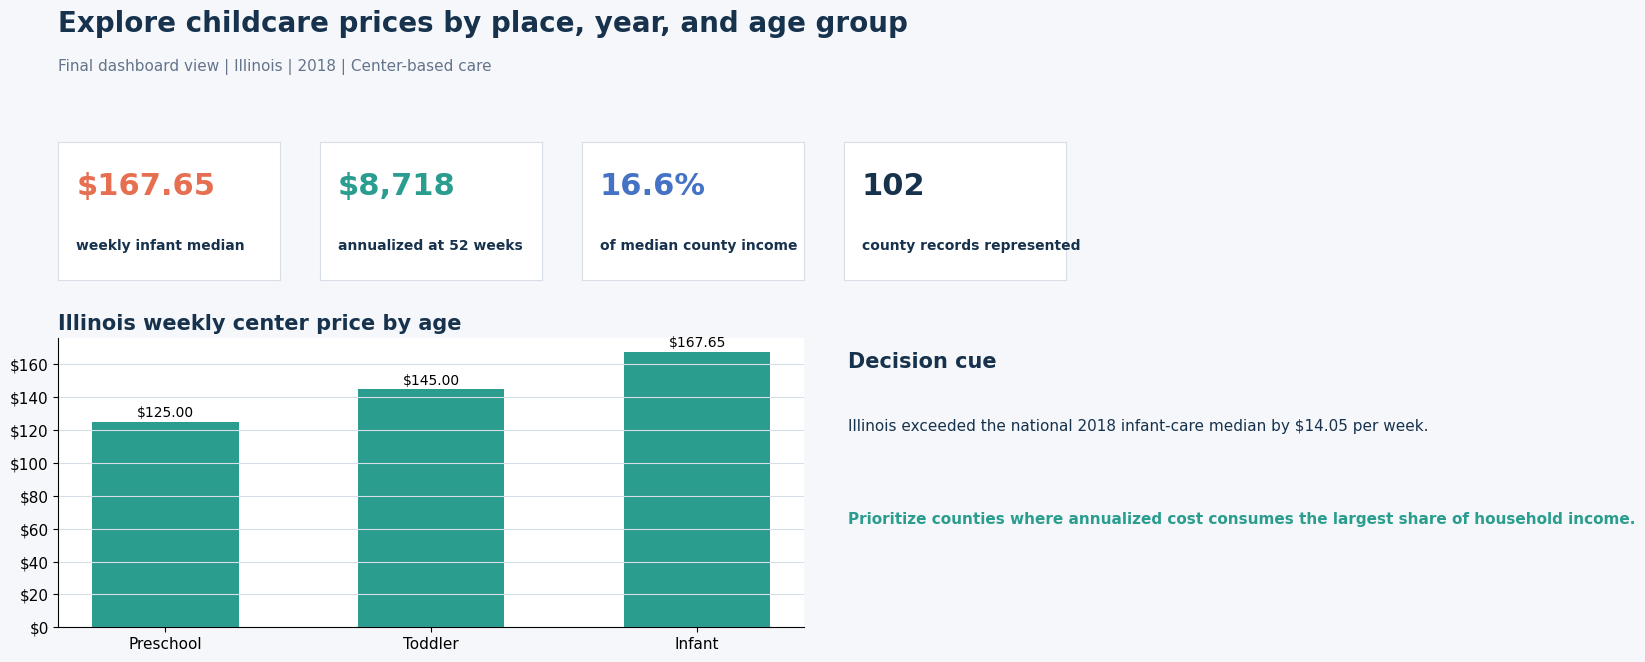

In [6]:
illinois = state_metrics.loc[state_metrics["State_Abbreviation"] == "IL"].iloc[0]

fig = plt.figure(figsize=(13, 8), facecolor="#F5F7FA")
grid = fig.add_gridspec(3, 4, height_ratios=[0.55, 1.05, 2.2], hspace=0.35, wspace=0.18)

header = fig.add_subplot(grid[0, :])
header.axis("off")
header.text(0.0, 0.72, "Explore childcare prices by place, year, and age group",
            fontsize=20, fontweight="bold", color=COLORS["navy"])
header.text(0.0, 0.18, "Final dashboard view | Illinois | 2018 | Center-based care",
            fontsize=11, color=COLORS["muted"])

kpis = [
    (f"${illinois['infant']:,.2f}", "weekly infant median", COLORS["coral"]),
    (f"${illinois['annual_infant']:,.0f}", "annualized at 52 weeks", COLORS["teal"]),
    (f"{illinois['burden']:.1%}", "of median county income", COLORS["blue"]),
    (f"{int(illinois['counties'])}", "county records represented", COLORS["navy"]),
]
for index, (value, label, color) in enumerate(kpis):
    card = fig.add_subplot(grid[1, index])
    card.set_facecolor("white")
    card.set_xticks([])
    card.set_yticks([])
    for spine in card.spines.values():
        spine.set_color("#D8DEE8")
    card.text(0.08, 0.62, value, transform=card.transAxes, fontsize=22,
              fontweight="bold", color=color)
    card.text(0.08, 0.22, label, transform=card.transAxes, fontsize=10,
              color=COLORS["navy"], fontweight="bold")

chart = fig.add_subplot(grid[2, :3])
age_labels = ["Preschool", "Toddler", "Infant"]
age_values = [illinois["preschool"], illinois["toddler"], illinois["infant"]]
age_bars = chart.bar(age_labels, age_values, color=COLORS["teal"], width=0.55)
chart.set_title("Illinois weekly center price by age", loc="left", fontsize=15, color=COLORS["navy"])
chart.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
chart.grid(True, axis="y", color="#D8DEE8", linewidth=0.8)
chart.xaxis.grid(False)
for spine in ("top", "right"):
    chart.spines[spine].set_visible(False)
for bar, value in zip(age_bars, age_values):
    chart.text(bar.get_x() + bar.get_width() / 2, value + 3, f"${value:,.2f}",
               ha="center", fontsize=10)

cue = fig.add_subplot(grid[2, 3])
cue.axis("off")
cue.text(0.02, 0.90, "Decision cue", fontsize=15, fontweight="bold", color=COLORS["navy"])
cue.text(0.02, 0.68,
         f"Illinois exceeded the national 2018 infant-care median by ${illinois['infant'] - infant_2018:,.2f} per week.",
         fontsize=11, color=COLORS["navy"], wrap=True)
cue.text(0.02, 0.36,
         "Prioritize counties where annualized cost consumes the largest share of household income.",
         fontsize=11, color=COLORS["teal"], fontweight="bold", wrap=True)

plt.show()


## 6. Optional interactive Plotly view

The chart below provides an interactive ranking. Use the dropdown to switch among infant, toddler, preschool, and affordability-burden measures. If Plotly is not installed, run `%pip install plotly` and execute the cell again.


In [7]:
try:
    import plotly.graph_objects as go

    valid = state_metrics.dropna(subset=["infant", "toddler", "preschool", "burden"]).copy()
    metrics = [
        ("infant", "Infant weekly price", "$,.2f"),
        ("toddler", "Toddler weekly price", "$,.2f"),
        ("preschool", "Preschool weekly price", "$,.2f"),
        ("burden", "Annual infant-care burden", ".1%"),
    ]

    interactive = go.Figure()
    for index, (column, label, fmt) in enumerate(metrics):
        ranked = valid.nlargest(15, column).sort_values(column)
        interactive.add_trace(go.Bar(
            x=ranked[column],
            y=ranked["State_Name"],
            orientation="h",
            name=label,
            visible=(index == 0),
            marker_color=COLORS["coral"] if column != "burden" else COLORS["teal"],
            hovertemplate="%{y}: %{x}<extra></extra>",
        ))

    buttons = []
    for index, (column, label, fmt) in enumerate(metrics):
        visible = [False] * len(metrics)
        visible[index] = True
        buttons.append({
            "label": label,
            "method": "update",
            "args": [
                {"visible": visible},
                {
                    "title": "Top 15 jurisdictions - " + label,
                    "xaxis": {"title": label, "tickformat": fmt},
                },
            ],
        })

    interactive.update_layout(
        title="Top 15 jurisdictions - Infant weekly price",
        template="plotly_white",
        height=650,
        showlegend=False,
        margin=dict(l=130, r=40, t=100, b=50),
        xaxis=dict(title="Infant weekly price", tickformat="$,.2f"),
        updatemenus=[{
            "buttons": buttons,
            "direction": "down",
            "x": 0.0,
            "y": 1.14,
            "xanchor": "left",
            "yanchor": "top",
        }],
    )
    interactive.show()
except ImportError:
    print("Plotly is not installed. Run %pip install plotly to display the interactive chart.")


Plotly is not installed. Run %pip install plotly to display the interactive chart.


## 7. Ethics, assumptions, and limitations

- The original values are county-level price estimates. They do not represent a bill paid by every household.
- State values are medians across reporting counties, which can hide variation within a state.
- Missing prices are not imputed. Jurisdictions without a reported 2018 infant-care value are excluded from the ranking and clearly identified.
- Annualized cost is a communication metric calculated as weekly price multiplied by 52; it is not a provider invoice.
- Affordability burden uses county median household income as a proxy. Household composition and income vary.
- Price does not measure availability, capacity, safety, or quality. Lower price should not be interpreted as better care.
- The data are publicly released, aggregated government statistics and contain no personally identifiable information.

These limitations are mitigated through labeled filters, visible source notes, median-based comparisons, and a recommendation to pair price information with access and quality measures before allocating funds.


## 8. References

- U.S. Department of Labor, Women's Bureau. *National Database of Childcare Prices*. https://www.dol.gov/agencies/wb/topics/featured-childcare
- Knaflic, C. N. (2015). *Storytelling with Data: A Data Visualization Guide for Business Professionals*. Wiley.
- Course-provided National Database of Childcare Prices workbook and project milestones prepared by Anil Bammidi.
